# Analyse des matchs internationaux de football (1872 – aujourd'hui)

Source : [martj42/international_results](https://github.com/martj42/international_results)

**Plan de l'analyse**
1. Chargement et qualité des données
2. Préparation (variables dérivées)
3. Évolution du football international dans le temps
4. Avantage du terrain
5. Compétitions
6. Les équipes
7. Les scores
8. Les buteurs
9. Les tirs au but
10. Zoom sur la France
11. Conclusions

## 1. Chargement et qualité des données

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_columns", None)

DATA = "data_foot/"
results     = pd.read_csv(DATA + "results.csv", parse_dates=["date"])
goals       = pd.read_csv(DATA + "goalscorers.csv", parse_dates=["date"])
shootouts   = pd.read_csv(DATA + "shootouts.csv", parse_dates=["date"])
former      = pd.read_csv(DATA + "former_names.csv")

for name, df in [("results", results), ("goalscorers", goals),
                 ("shootouts", shootouts), ("former_names", former)]:
    print(f"{name:13s} : {df.shape[0]:>6} lignes x {df.shape[1]} colonnes")

results       :  49945 lignes x 9 colonnes
goalscorers   :  47914 lignes x 9 colonnes
shootouts     :    700 lignes x 5 colonnes
former_names  :     36 lignes x 4 colonnes


In [6]:
results.head()

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False


In [7]:
results.info()

<class 'pandas.DataFrame'>
RangeIndex: 49945 entries, 0 to 49944
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        49945 non-null  datetime64[us]
 1   home_team   49945 non-null  str           
 2   away_team   49945 non-null  str           
 3   home_score  49945 non-null  int64         
 4   away_score  49945 non-null  int64         
 5   tournament  49945 non-null  str           
 6   city        49945 non-null  str           
 7   country     49945 non-null  str           
 8   neutral     49945 non-null  bool          
dtypes: bool(1), datetime64[us](1), int64(2), str(5)
memory usage: 3.1 MB


### Valeurs manquantes et doublons

In [8]:
for name, df in [("results", results), ("goalscorers", goals), ("shootouts", shootouts)]:
    print(f"--- {name} ---")
    na = df.isna().sum()
    print(na[na > 0].to_string() if na.any() else "aucune valeur manquante")
    print("doublons :", df.duplicated().sum(), "\n")

--- results ---
aucune valeur manquante
doublons : 0 

--- goalscorers ---
scorer       44
minute      254
assist    45838
doublons : 79 

--- shootouts ---
first_shooter    431
doublons : 0 



Le fichier peut contenir des matchs **à venir** déjà programmés, sans score. On les retire s'il y en a.

Dans `goalscorers.csv`, l'absence de passeur (`assist`) est normale, car l'information n'est renseignée que pour les matchs récents.

In [9]:
upcoming = results[results["home_score"].isna()]
print(f"{len(upcoming)} matchs à venir retirés")
results = results.dropna(subset=["home_score", "away_score"]).copy()
results[["home_score", "away_score"]] = results[["home_score", "away_score"]].astype(int)
print("Période couverte :", results["date"].min().date(), "->", results["date"].max().date())

0 matchs à venir retirés
Période couverte : 1872-11-30 -> 2026-10-06


## 2. Préparation des données

In [10]:
results["year"]        = results["date"].dt.year
results["decade"]      = (results["year"] // 10) * 10
results["total_goals"] = results["home_score"] + results["away_score"]
results["goal_diff"]   = results["home_score"] - results["away_score"]
results["outcome"] = np.select(
    [results["goal_diff"] > 0, results["goal_diff"] < 0],
    ["Victoire domicile", "Victoire extérieur"],
    default="Nul",
)
results["winner"] = np.select(
    [results["goal_diff"] > 0, results["goal_diff"] < 0],
    [results["home_team"], results["away_team"]],
    default=None,
)
results[["date", "home_team", "away_team", "home_score", "away_score", "outcome", "total_goals"]].tail()

,date,home_team,away_team,home_score,away_score,outcome,total_goals
49940,2026-10-06,Belize,French Guiana,0,1,Victoire extérieur,1
49941,2026-10-06,Turks and Caicos Islands,Montserrat,1,4,Victoire extérieur,5
49942,2026-10-06,Antigua and Barbuda,Aruba,3,2,Victoire domicile,5
49943,2026-10-06,Saint Martin,Bahamas,6,0,Victoire domicile,6
49944,2026-10-06,Saudi Arabia,United Arab Emirates,2,0,Victoire domicile,2


On construit aussi une table **« longue »** : une ligne par équipe et par match. C'est plus pratique pour calculer des statistiques par équipe.

In [11]:
home = results.rename(columns={"home_team": "team", "away_team": "opponent",
                               "home_score": "gf", "away_score": "ga"})
home["venue"] = np.where(home["neutral"], "Neutre", "Domicile")
away = results.rename(columns={"away_team": "team", "home_team": "opponent",
                               "away_score": "gf", "home_score": "ga"})
away["venue"] = np.where(away["neutral"], "Neutre", "Extérieur")

cols = ["date", "year", "decade", "tournament", "team", "opponent", "gf", "ga", "venue"]
team_matches = pd.concat([home[cols], away[cols]], ignore_index=True)
team_matches["result"] = np.select(
    [team_matches["gf"] > team_matches["ga"], team_matches["gf"] < team_matches["ga"]],
    ["V", "D"], default="N")
team_matches["points"] = team_matches["result"].map({"V": 3, "N": 1, "D": 0})
team_matches.sample(5, random_state=0)

,date,year,decade,tournament,team,opponent,gf,ga,venue,result,points
50249,1911-03-26,1911,1910,Friendly,Switzerland,Germany,2,6,Extérieur,D,0
82111,2008-07-13,2008,2000,Viva World Cup,Arameans Suryoye,Padania,0,2,Neutre,D,0
17837,1991-06-25,1991,1990,Island Games,Åland Islands,Guernsey,2,0,Domicile,V,3
86317,2012-10-16,2012,2010,FIFA World Cup qualification,Kazakhstan,Austria,0,4,Extérieur,D,0
89984,2016-09-03,2016,2010,African Cup of Nations qualification,Mauritius,Mozambique,0,1,Extérieur,D,0


## 3. Évolution du football international dans le temps

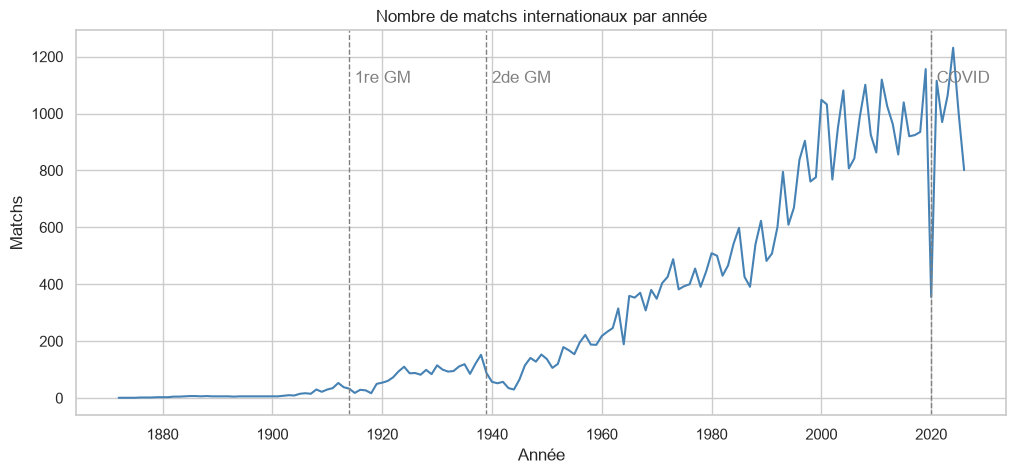

In [12]:
per_year = results.groupby("year").size()
ax = per_year.plot(color="steelblue")
ax.set(title="Nombre de matchs internationaux par année", xlabel="Année", ylabel="Matchs")
for y, label in [(1914, "1re GM"), (1939, "2de GM"), (2020, "COVID")]:
    ax.axvline(y, color="grey", ls="--", lw=1)
    ax.text(y + 1, per_year.max() * 0.9, label, color="grey")
plt.show()

On voit nettement les creux liés aux deux guerres mondiales et à la pandémie de 2020. Le nombre de matchs explose à partir des années 1990, avec l'indépendance de nombreux pays (ex-URSS, ex-Yougoslavie) et la multiplication des qualifications.

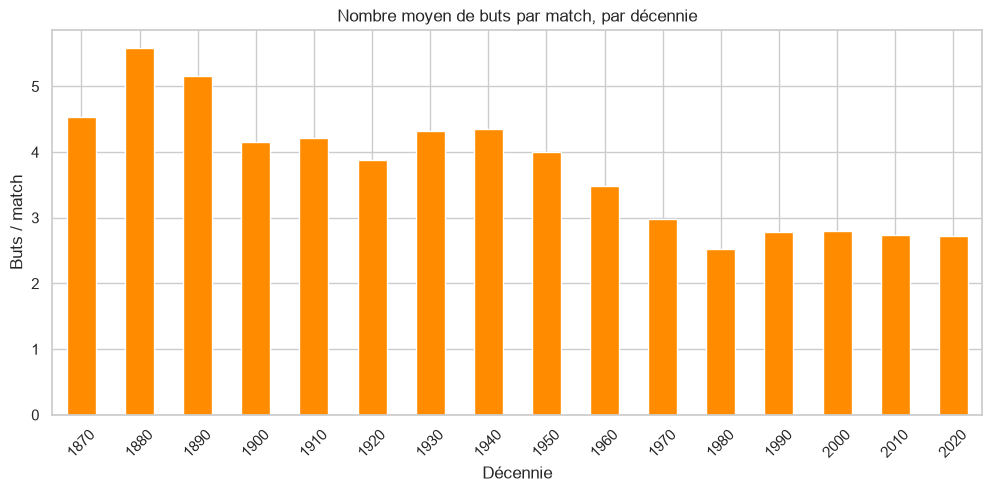

decade,1870,1880,1890,1900,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010,2020
buts/match,4.54,5.58,5.15,4.16,4.22,3.88,4.32,4.34,4.0,3.48,2.98,2.53,2.78,2.8,2.74,2.73


In [13]:
goals_decade = results.groupby("decade")["total_goals"].mean()
ax = goals_decade.plot(kind="bar", color="darkorange")
ax.set(title="Nombre moyen de buts par match, par décennie", xlabel="Décennie", ylabel="Buts / match")
plt.xticks(rotation=45)
plt.show()
goals_decade.round(2).to_frame("buts/match").T

Le nombre de buts par match baisse régulièrement, de plus de 4,5 buts au XIXe siècle à environ 2,5 dans les années 1980. Il se stabilise ensuite autour de 2,7 à 2,8. Cela reflète la professionnalisation du jeu et l'amélioration des organisations défensives.

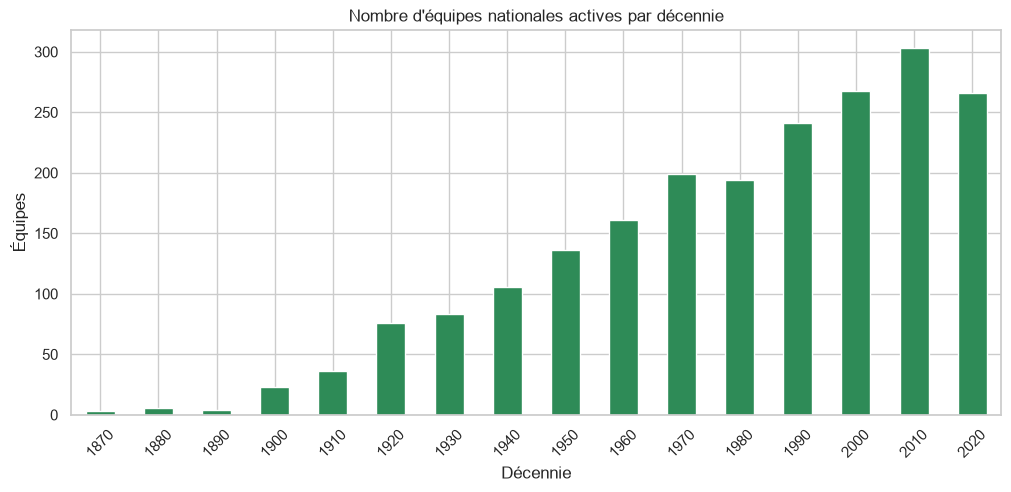

In [14]:
nb_teams = team_matches.groupby("decade")["team"].nunique()
ax = nb_teams.plot(kind="bar", color="seagreen")
ax.set(title="Nombre d'équipes nationales actives par décennie", xlabel="Décennie", ylabel="Équipes")
plt.xticks(rotation=45)
plt.show()

## 4. L'avantage du terrain

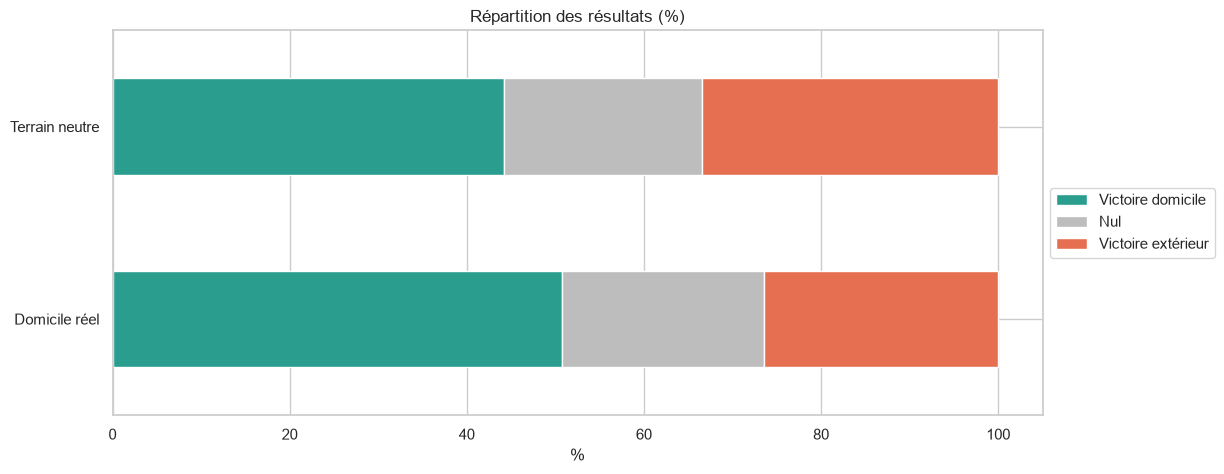

outcome,Victoire domicile,Nul,Victoire extérieur
neutral,,,
Domicile réel,50.7,22.8,26.4
Terrain neutre,44.2,22.4,33.4


In [15]:
outcome_by_venue = (pd.crosstab(results["neutral"].map({True: "Terrain neutre", False: "Domicile réel"}),
                                results["outcome"], normalize="index") * 100)
outcome_by_venue = outcome_by_venue[["Victoire domicile", "Nul", "Victoire extérieur"]]
ax = outcome_by_venue.plot(kind="barh", stacked=True, color=["#2a9d8f", "#bdbdbd", "#e76f51"])
ax.set(title="Répartition des résultats (%)", xlabel="%", ylabel="")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()
outcome_by_venue.round(1)

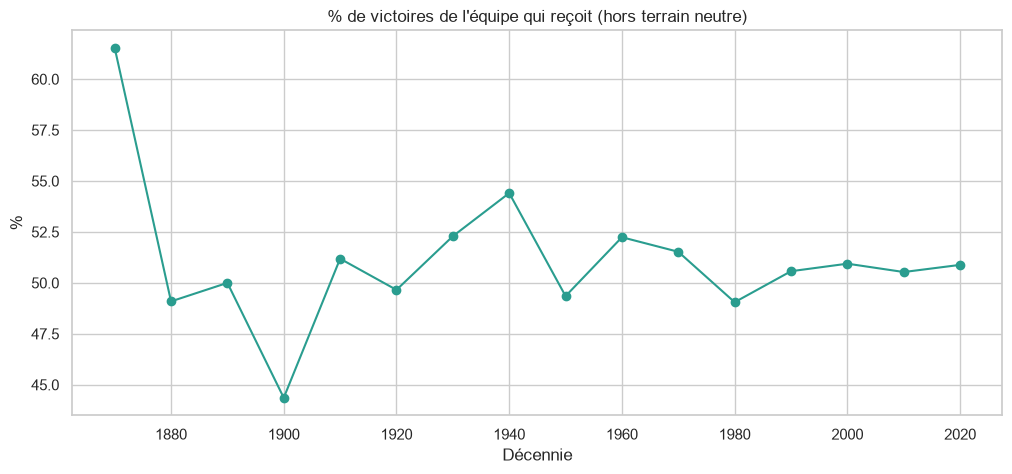

In [16]:
home_adv = (results[~results["neutral"]]
            .groupby("decade")["outcome"]
            .apply(lambda s: (s == "Victoire domicile").mean() * 100))
ax = home_adv.plot(marker="o", color="#2a9d8f")
ax.set(title="% de victoires de l'équipe qui reçoit (hors terrain neutre)",
       xlabel="Décennie", ylabel="%")
plt.show()

L'équipe qui joue à domicile gagne environ **51 %** de ses matchs, et l'équipe qui se déplace environ **26 %**. Sur terrain neutre, l'écart se réduit (44 % contre 33 %). L'équipe citée en premier y est souvent la mieux classée ou le pays organisateur. Depuis 1880, l'avantage du terrain reste remarquablement **stable**, autour de 50 % de victoires à domicile.

## 5. Les compétitions

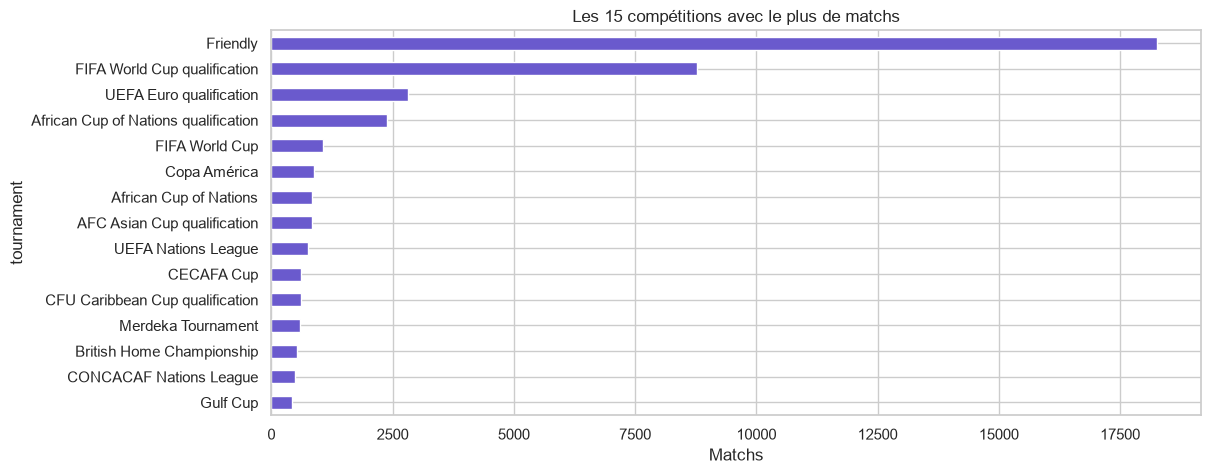

In [17]:
top_tournaments = results["tournament"].value_counts().head(15)
ax = top_tournaments.sort_values().plot(kind="barh", color="slateblue")
ax.set(title="Les 15 compétitions avec le plus de matchs", xlabel="Matchs")
plt.show()

In [18]:
goals_by_tournament = (results.groupby("tournament")
                       .agg(matchs=("total_goals", "size"), buts_par_match=("total_goals", "mean"))
                       .query("matchs >= 300")
                       .sort_values("buts_par_match", ascending=False))
goals_by_tournament.round(2)

,matchs,buts_par_match
tournament,,
Island Games,394,3.98
British Home Championship,523,3.52
CFU Caribbean Cup qualification,606,3.51
Asian Games,368,3.32
AFC Asian Cup qualification,829,3.29
Merdeka Tournament,599,3.27
CONCACAF Nations League,495,3.21
Copa América,869,3.14
FIFA World Cup qualification,8771,2.89


## 6. Les équipes

In [19]:
team_stats = (team_matches.groupby("team")
              .agg(matchs=("result", "size"),
                   victoires=("result", lambda s: (s == "V").sum()),
                   nuls=("result", lambda s: (s == "N").sum()),
                   defaites=("result", lambda s: (s == "D").sum()),
                   buts_pour=("gf", "sum"),
                   buts_contre=("ga", "sum"),
                   points=("points", "sum")))
team_stats["%_victoires"]    = (team_stats["victoires"] / team_stats["matchs"] * 100).round(1)
team_stats["pts_par_match"]  = (team_stats["points"] / team_stats["matchs"]).round(2)
team_stats["diff_buts"]      = team_stats["buts_pour"] - team_stats["buts_contre"]

print("Équipes ayant joué le plus de matchs :")
team_stats.sort_values("matchs", ascending=False).head(10)

Équipes ayant joué le plus de matchs :


,matchs,victoires,nuls,defaites,buts_pour,buts_contre,points,%_victoires,pts_par_match,diff_buts
team,,,,,,,,,,
Sweden,1109,545,235,329,2185,1434,1870,49.1,1.69,751
England,1102,634,259,209,2415,1056,2161,57.5,1.96,1359
Argentina,1079,602,256,221,2058,1082,2062,55.8,1.91,976
Brazil,1067,677,218,172,2324,964,2249,63.4,2.11,1360
Germany,1039,602,216,221,2334,1205,2022,57.9,1.95,1129
Hungary,1010,474,223,313,2014,1485,1645,46.9,1.63,529
Mexico,1010,517,232,261,1776,1063,1783,51.2,1.77,713
South Korea,1004,538,251,215,1785,910,1865,53.6,1.86,875
Uruguay,979,433,242,304,1556,1185,1541,44.2,1.57,371


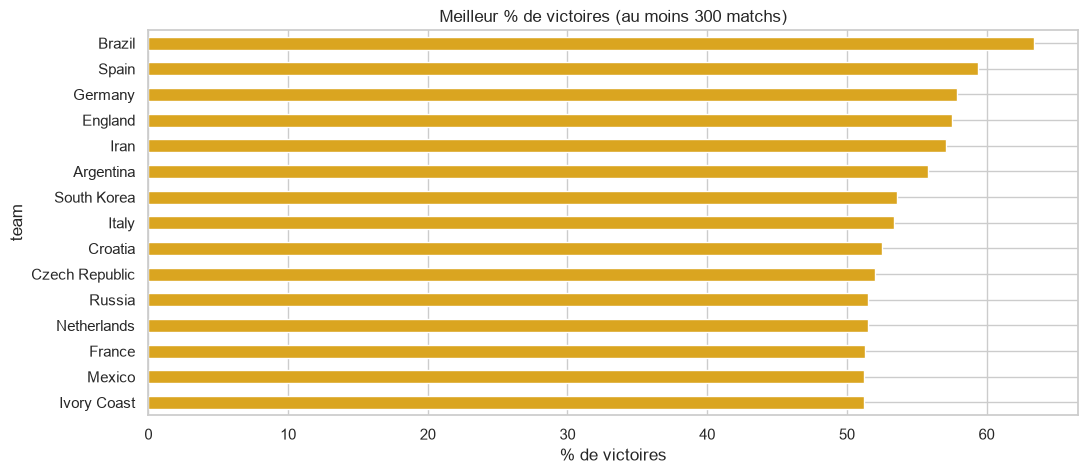

,matchs,victoires,nuls,defaites,buts_pour,buts_contre,points,%_victoires,pts_par_match,diff_buts
team,,,,,,,,,,
Brazil,1067,677,218,172,2324,964,2249,63.4,2.11,1360
Spain,795,472,183,140,1628,709,1599,59.4,2.01,919
Germany,1039,602,216,221,2334,1205,2022,57.9,1.95,1129
England,1102,634,259,209,2415,1056,2161,57.5,1.96,1359
Iran,622,355,146,121,1183,491,1211,57.1,1.95,692
Argentina,1079,602,256,221,2058,1082,2062,55.8,1.91,976
South Korea,1004,538,251,215,1785,910,1865,53.6,1.86,875
Italy,897,479,244,174,1573,881,1681,53.4,1.87,692
Croatia,404,212,104,88,698,421,740,52.5,1.83,277


In [20]:
MIN_MATCHS = 300
best = (team_stats.query("matchs >= @MIN_MATCHS")
        .sort_values("%_victoires", ascending=False).head(15))
ax = best["%_victoires"].sort_values().plot(kind="barh", color="goldenrod")
ax.set(title=f"Meilleur % de victoires (au moins {MIN_MATCHS} matchs)", xlabel="% de victoires")
plt.show()
best

Ce classement est biaisé, car toutes les équipes n'ont pas affronté des adversaires de même niveau. On le refait en ne gardant que les **matchs officiels**, c'est-à-dire sans les matchs amicaux, et sur la période récente (depuis 2000).

In [21]:
recent_official = team_matches[(team_matches["year"] >= 2000) & (team_matches["tournament"] != "Friendly")]
recent_rank = (recent_official.assign(gd=recent_official["gf"] - recent_official["ga"])
               .groupby("team")
               .agg(matchs=("points", "size"), pts_par_match=("points", "mean"),
                    diff_buts_moy=("gd", "mean"))
               .query("matchs >= 100"))
recent_rank.sort_values("pts_par_match", ascending=False).head(15).round(2)

,matchs,pts_par_match,diff_buts_moy
team,,,
Spain,235,2.33,1.60
Germany,214,2.15,1.50
England,214,2.15,1.52
Netherlands,213,2.14,1.44
France,222,2.13,1.17
Portugal,226,2.10,1.33
Iran,233,2.09,1.38
Italy,220,2.03,0.91
Argentina,224,2.02,0.91


## 7. Les scores

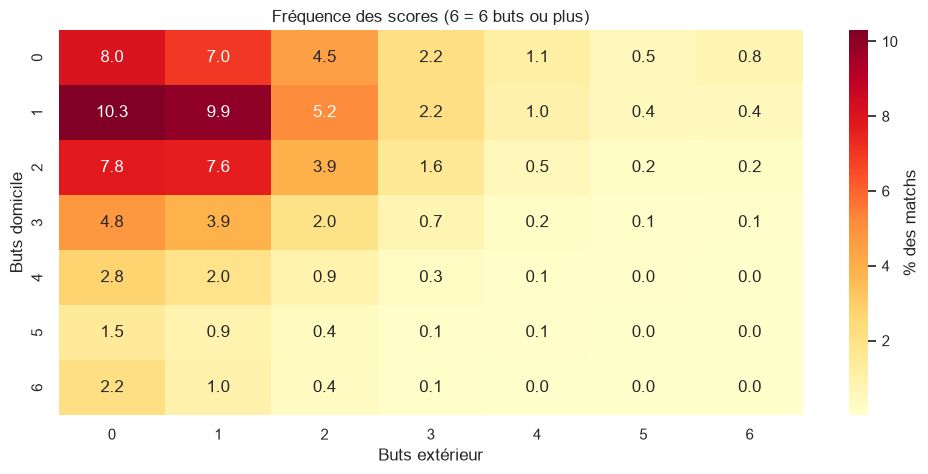

Scores les plus fréquents :


1-0    5144
1-1    4953
0-0    4004
2-0    3885
2-1    3810
0-1    3492
1-2    2576
3-0    2394
0-2    2259
2-2    1960
Name: count, dtype: int64

In [22]:
capped = results.assign(h=results["home_score"].clip(upper=6), a=results["away_score"].clip(upper=6))
score_matrix = pd.crosstab(capped["h"], capped["a"], normalize=True) * 100
ax = sns.heatmap(score_matrix, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "% des matchs"})
ax.set(title="Fréquence des scores (6 = 6 buts ou plus)", xlabel="Buts extérieur", ylabel="Buts domicile")
plt.show()

print("Scores les plus fréquents :")
(results["home_score"].astype(str) + "-" + results["away_score"].astype(str)).value_counts().head(10)

In [23]:
print("Les 10 plus larges victoires de l'histoire :")
(results.assign(ecart=results["goal_diff"].abs())
 .sort_values("ecart", ascending=False)
 [["date", "home_team", "home_score", "away_score", "away_team", "tournament"]]
 .head(10))

Les 10 plus larges victoires de l'histoire :


,date,home_team,home_score,away_score,away_team,tournament
25437,2001-04-11,Australia,31,0,American Samoa,FIFA World Cup qualification
8553,1971-09-13,Tahiti,30,0,Cook Islands,South Pacific Games
11921,1979-08-30,Fiji,24,0,Kiribati,South Pacific Games
37079,2013-06-24,Provence,22,0,Tibet,"International Tournament of Peoples, Cultures ..."
25434,2001-04-09,Australia,22,0,Tonga,FIFA World Cup qualification
29060,2005-03-11,Guam,0,21,North Korea,EAFF Championship
37077,2013-06-23,Quebec,21,0,Tibet,"International Tournament of Peoples, Cultures ..."
6586,1966-04-03,Libya,21,0,Oman,Arab Cup
30536,2006-11-24,Sápmi,21,1,Monaco,Viva World Cup
27359,2003-06-30,Sark,0,20,Isle of Wight,Island Games


## 8. Les buteurs

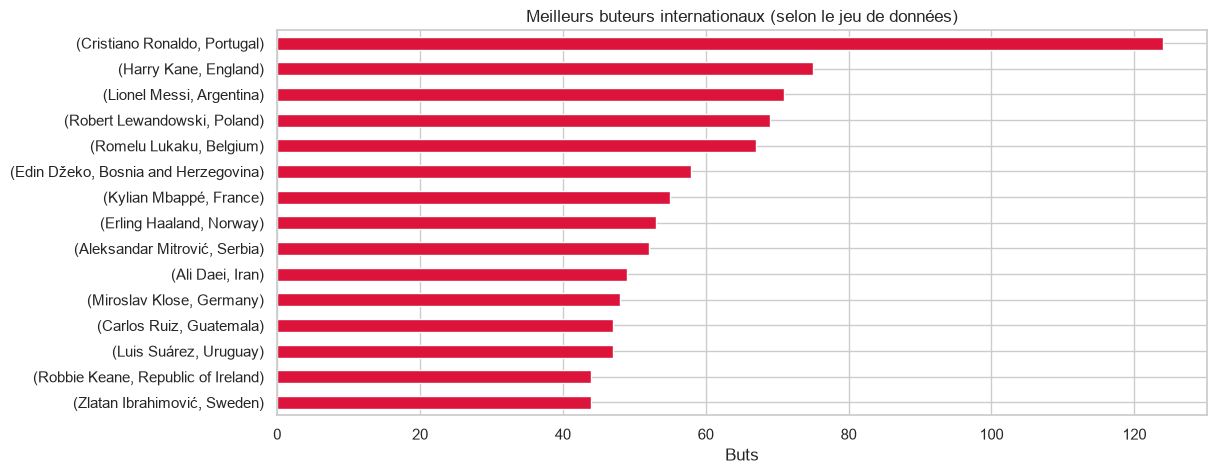

In [24]:
goals["minute"] = pd.to_numeric(goals["minute"], errors="coerce")
real_goals = goals[~goals["own_goal"]]

top_scorers = (real_goals.groupby(["scorer", "team"]).size()
               .sort_values(ascending=False).head(15))
ax = top_scorers.sort_values().plot(kind="barh", color="crimson")
ax.set(title="Meilleurs buteurs internationaux (selon le jeu de données)", xlabel="Buts", ylabel="")
plt.show()

⚠️ Le fichier `goalscorers.csv` ne couvre qu'une partie des matchs, surtout les grandes compétitions. Les totaux peuvent donc être inférieurs aux chiffres officiels.

In [25]:
coverage = goals[["date", "home_team", "away_team"]].drop_duplicates().shape[0]
print(f"Matchs avec détail des buteurs : {coverage} / {len(results)} ({coverage/len(results):.0%})")

Matchs avec détail des buteurs : 15540 / 49945 (31%)


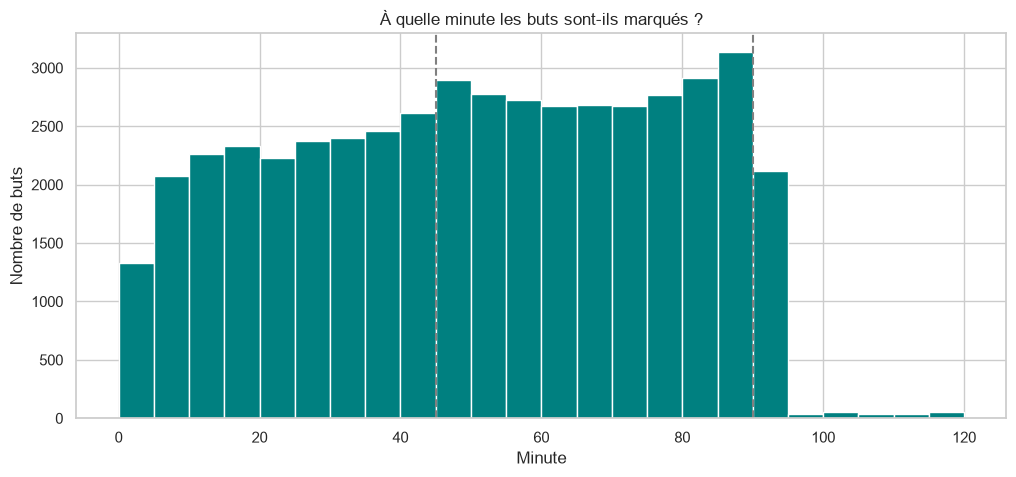

,% des buts
periode,
0-15,13.0
16-30,14.6
31-45,16.8
46-60,16.6
61-75,17.0
76-90,21.5
Prolongation,0.6


In [26]:
fig, ax = plt.subplots()
ax.hist(goals["minute"].dropna().clip(upper=120), bins=range(0, 125, 5), color="teal", edgecolor="white")
ax.set(title="À quelle minute les buts sont-ils marqués ?", xlabel="Minute", ylabel="Nombre de buts")
ax.axvline(45, color="grey", ls="--"); ax.axvline(90, color="grey", ls="--")
plt.show()

goals["periode"] = pd.cut(goals["minute"], bins=[0, 15, 30, 45, 60, 75, 90, 130],
                          labels=["0-15", "16-30", "31-45", "46-60", "61-75", "76-90", "Prolongation"])
(goals["periode"].value_counts(normalize=True).sort_index() * 100).round(1).to_frame("% des buts")

Les buts sont plus nombreux en **fin de match** : plus de 21 % sont marqués entre la 76e et la 90e minute, contre 13 % dans le premier quart d'heure. La fatigue gagne et les équipes prennent plus de risques. On observe aussi des pics juste avant 45' et 90', car les buts du temps additionnel sont notés à ces minutes.

In [27]:
print(f"Penalties  : {goals['penalty'].mean():.1%} des buts")
print(f"CSC        : {goals['own_goal'].mean():.1%} des buts")

Penalties  : 6.8% des buts
CSC        : 2.0% des buts


## 9. Les tirs au but

In [28]:
so = shootouts.copy()
so["loser"] = np.where(so["winner"] == so["home_team"], so["away_team"], so["home_team"])
wins = so["winner"].value_counts()
losses = so["loser"].value_counts()
so_stats = pd.DataFrame({"gagnées": wins, "perdues": losses}).fillna(0).astype(int)
so_stats["total"] = so_stats.sum(axis=1)
so_stats["%_réussite"] = (so_stats["gagnées"] / so_stats["total"] * 100).round(1)
print("Équipes ayant disputé au moins 10 séances, triées par réussite :")
so_stats.query("total >= 10").sort_values("%_réussite", ascending=False).head(15)

Équipes ayant disputé au moins 10 séances, triées par réussite :


,gagnées,perdues,total,%_réussite
Indonesia,11,2,13,84.6
Saudi Arabia,9,2,11,81.8
Guinea,8,2,10,80.0
Iraq,12,4,16,75.0
Angola,7,3,10,70.0
Argentina,15,8,23,65.2
Croatia,7,4,11,63.6
Kenya,10,6,16,62.5
Botswana,8,5,13,61.5
Mozambique,8,5,13,61.5


### Tirer en premier est-il un avantage ?

In [29]:
known = so.dropna(subset=["first_shooter"])
p = (known["first_shooter"] == known["winner"]).mean()
print(f"Séances où l'on connaît le premier tireur : {len(known)}")
print(f"L'équipe qui tire en premier gagne dans {p:.1%} des cas")

Séances où l'on connaît le premier tireur : 269
L'équipe qui tire en premier gagne dans 52.4% des cas


## 10. Zoom sur la France

Change la variable `TEAM` pour analyser une autre sélection.

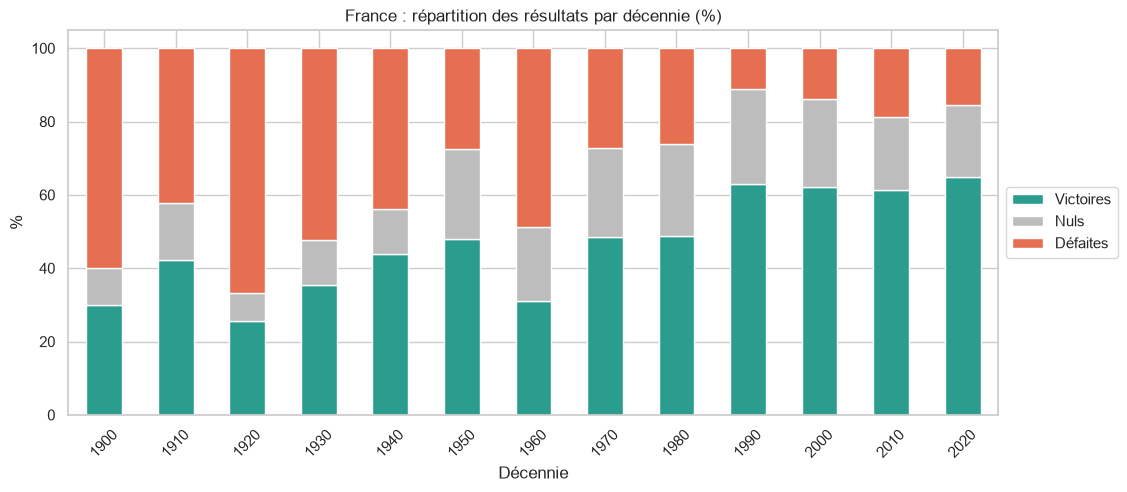

In [30]:
TEAM = "France"
fr = team_matches[team_matches["team"] == TEAM]

by_decade = fr.groupby("decade")["result"].value_counts(normalize=True).unstack().fillna(0)[["V", "N", "D"]] * 100
ax = by_decade.plot(kind="bar", stacked=True, color=["#2a9d8f", "#bdbdbd", "#e76f51"])
ax.set(title=f"{TEAM} : répartition des résultats par décennie (%)", xlabel="Décennie", ylabel="%")
ax.legend(["Victoires", "Nuls", "Défaites"], loc="center left", bbox_to_anchor=(1, 0.5))
plt.xticks(rotation=45)
plt.show()

In [31]:
h2h = (fr.groupby("opponent")
       .agg(matchs=("result", "size"),
            V=("result", lambda s: (s == "V").sum()),
            N=("result", lambda s: (s == "N").sum()),
            D=("result", lambda s: (s == "D").sum()),
            bp=("gf", "sum"), bc=("ga", "sum"))
       .sort_values("matchs", ascending=False))
print(f"Adversaires les plus fréquents de {TEAM} :")
h2h.head(10)

Adversaires les plus fréquents de France :


,matchs,V,N,D,bp,bc
opponent,,,,,,
Belgium,80,31,19,30,141,164
Italy,43,13,11,19,63,87
Spain,39,13,7,19,44,73
Switzerland,39,16,11,12,70,63
England,35,11,6,18,49,81
Germany,35,16,8,11,53,50
Netherlands,31,15,5,11,53,57
Portugal,27,17,4,6,48,29
Austria,26,14,3,9,43,41


In [32]:
def face_a_face(team_a, team_b):
    """Bilan des confrontations entre deux équipes."""
    d = team_matches[(team_matches["team"] == team_a) & (team_matches["opponent"] == team_b)]
    print(f"{team_a} vs {team_b} : {len(d)} matchs | "
          f"{(d['result']=='V').sum()} V - {(d['result']=='N').sum()} N - {(d['result']=='D').sum()} D | "
          f"buts {d['gf'].sum()}-{d['ga'].sum()}")
    return d.sort_values("date", ascending=False)[["date", "tournament", "gf", "ga", "venue"]].head(5)

face_a_face("France", "Germany")

France vs Germany : 35 matchs | 16 V - 8 N - 11 D | buts 53-50


,date,tournament,gf,ga,venue
98386,2025-06-08,UEFA Nations League,2,0,Extérieur
47143,2024-03-23,Friendly,0,2,Domicile
96441,2023-09-12,Friendly,1,2,Extérieur
94127,2021-06-15,UEFA Euro,1,0,Extérieur
42006,2018-10-16,UEFA Nations League,2,1,Domicile


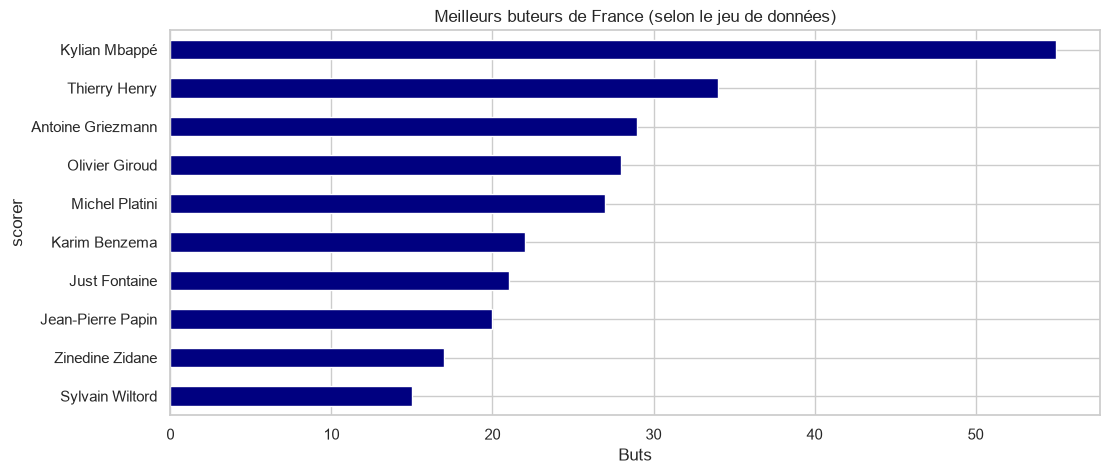

In [33]:
fr_scorers = real_goals[real_goals["team"] == TEAM]["scorer"].value_counts().head(10)
ax = fr_scorers.sort_values().plot(kind="barh", color="navy")
ax.set(title=f"Meilleurs buteurs de {TEAM} (selon le jeu de données)", xlabel="Buts")
plt.show()

## 11. Conclusions

- **Volume** : le football international s'est fortement développé. On compte quelques matchs par an au XIXe siècle et plus de 1 000 par an aujourd'hui, avec des creux pendant les guerres et la pandémie de COVID.
- **Buts** : la moyenne de buts par match baisse sur le long terme, de 4 à 5 avant 1950 à environ 2,7 depuis 1990.
- **Avantage du terrain** : il est net et stable dans le temps, puisque l'équipe qui reçoit gagne environ 2 fois plus souvent que l'équipe qui se déplace (51 % contre 26 %).
- **Scores** : les scores les plus fréquents sont 1-0, 1-1 et 0-0. Les écarts records (31-0, Australie - Samoa américaines en 2001) opposent des sélections de niveaux très différents.
- **Équipes** : le Brésil a le meilleur bilan historique (63 % de victoires). Depuis 2000, en matchs officiels, l'Espagne domine (2,33 points par match).
- **Buteurs** : les buts tombent plus souvent en fin de match. Les penalties représentent environ 7 % des buts et les CSC environ 2 %. Attention : le détail des buteurs ne couvre qu'environ 31 % des matchs.
- **Tirs au but** : l'équipe qui tire en premier gagne dans 52 % des cas, sur environ 270 séances. C'est un avantage très faible et peu significatif.

**Pistes pour aller plus loin** : calculer un classement Elo, construire un modèle de prédiction du résultat (régression logistique ou forêt aléatoire), ou intégrer les anciens noms de pays avec `former_names.csv`.